In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import random
from pathlib import Path
import datetime
import pickle

sys.path.insert(0, "./cellular_cycle")
sys.path.insert(0, "./figures")

import fracprolif as fp
from cell_cycle_death_model import model
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator
from model_fxns import *
from Cell_Population_Simulation import Cell_Population_Simulation
from SMs_G1s_IMTs_extraction import SMs_G1s_IMTs_extraction
from call_cell_events import call_events #
from retrieve_cellState_dw_2 import retrieve_cellState #

In [2]:
# Directory containing cell fate data
DATADIR = Path('../data/Exp_Intermitotic_Times/')

# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

SAVE_CELL_DATA = False

In [3]:
# import pysb sampled parameters
sampled_parameter_names = np.loadtxt('model_data/sampled_parameter_names.txt', dtype=str)

In [4]:
# Importing the parameters:
new_param = pd.read_csv('test_treatments/parameters.csv')
for key in new_param.keys():
    try:
        if model.parameters[key].value != new_param[key][0]:
            model.parameters[key].value = new_param[key]
    except:
        print(key)
model.parameters['omega'].value = 200

Stress
b
Hippo_tot
Yap_tot
AKT_tot
ERK_tot
FAK_tot
skp2_tot
p21_tot
cdh1_tot
CycD_tot
K_1E2F
V_1E2F
k_cd4
k_myc1
k_CE
d_CE
K_i13
K_i14
V_sac
V_da
V_sec
V_de
V_sf
V_fs
V_dfa
v_scdh1a
v_2fak
v_s2p21
K_AFAK
K_dfa
K_fs
K_cf
K_cac
K_cec
K_da
K_de
K_sp21
k_dcdh1a
K_p21fak.1
k_CDF
K_DF
K_dcescp2


In [5]:
# Setting initial concentrations '/../model_data/initial_concentrations.csv'
initial_concentrations = pd.read_csv('model_data/initial_concentrations.csv')
for key in initial_concentrations.keys():
    try:
        model.parameters[key].value = initial_concentrations[key][0] / model.parameters['omega'].value
    except:
        print(key)

BAXm_0
BCL2_0


In [6]:
initial_concentrations

,Skp2_0,p21_0,p21p_0,cdh1act_0,cdh1inact_0,Myc_0,CycD_0,CycDp21_0,pRb_0,pRbp_0,...,CycAp21_0,CycB_0,CycBp21_0,Cdc20_0,BAX_0,BAXmBCL2_0,BH3_0,BH3BCL2_0,BAXm_0,BCL2_0
0,12.0,1.0,16.0,6.0,194.0,139.0,47.0,1.0,5.0,242.0,...,2.0,17.0,2.0,6.0,179.0,20.0,1.0,104.0,0.0,183.0


In [7]:
# Import ECM_conditions.csv
ECM_conditions = pd.read_csv('model_data/ECM_conditions_2.csv')
ECM_conditions


,condition,stiffness,drug,species,value
0,55 kPa DMSO,55 kPa,DMSO,AKT,1.0
1,55 kPa DMSO,55 kPa,DMSO,ERK,1.0
2,55 kPa DMSO,55 kPa,DMSO,FAK,1.0
3,4 kPa DMSO,4 kPa,DMSO,AKT,1.0
4,4 kPa DMSO,4 kPa,DMSO,ERK,1.0
5,4 kPa DMSO,4 kPa,DMSO,FAK,0.6
6,0.6 kPa DMSO,0.6 kPa,DMSO,AKT,0.6
7,0.6 kPa DMSO,0.6 kPa,DMSO,ERK,1.0
8,0.6 kPa DMSO,0.6 kPa,DMSO,FAK,0.4
9,55 kPa erlotinib,55 kPa,erlotinib,AKT,0.6


<Axes: xlabel='Time (h)', ylabel='Concentration'>

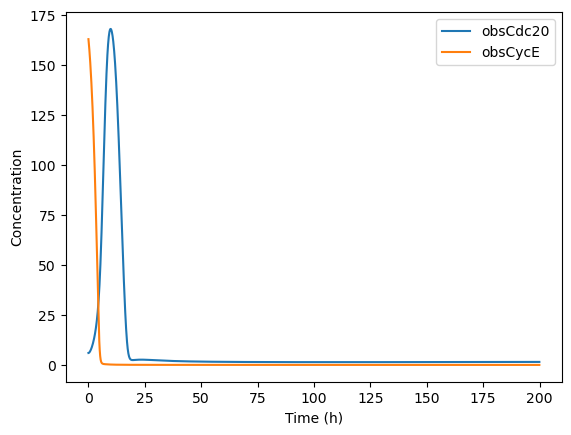

In [111]:
condition = "55 kPa erlotinib"

t = np.linspace(0, 20000, 200001)

model.parameters['AKT'].value = 0
model.parameters['ERK'].value = 0
model.parameters['FAK'].value = 0
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, verbose=False, compiler='python').run() #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,2000), legend=True)


In [129]:
Initial=[]
for j in range(len(model.observables)):
    name = model.observables[j].name
    val = sim_ode.all[name][-1]
    Initial.append(val)
Initial = [0 if i < 0 else i for i in Initial]

In [130]:
Initial

[1.2849547097662433,
 2653.1221560000877,
 0.14964184297369862,
 199.99210354672377,
 0.007896453275527867,
 6.720239241440258e-292,
 2.4043122295696e-255,
 1.641482854938894e-251,
 233.33316155557645,
 0.00017177775687283366,
 0,
 2.7578081893290015e-107,
 0.005055583563443688,
 0.26826161561157225,
 2.0435606018082777e-06,
 0.0001355456212220173,
 0.013564676884495936,
 0.10796667945787407,
 0.003700136041434389,
 182.67396820453837,
 16.279537468460187,
 0.20937266729849263,
 115.04062733270152,
 0.04691191491977292,
 175.82524606223762,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0,
 0.0]

In [131]:
t = np.linspace(0, 1000000, 100001)
sim_ode = ScipyOdeSimulator(model, t, initials=Initial, verbose=False, compiler='python').run()


<Axes: xlabel='Time (h)', ylabel='Concentration'>

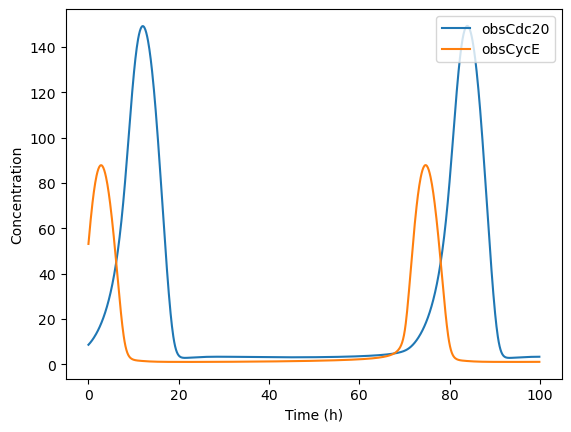

In [140]:
observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,1000), legend=True)

In [148]:
np.argmax(sim_ode.all['obsCdc20'][-10000:])

1458

In [135]:
init_off = Initial

In [149]:
Initial=[]
for j in range(len(model.observables)):
    name = model.observables[j].name
    max_ind = np.argmax(sim_ode.all['obsCdc20'][-10000:])
    val = sim_ode.all[name][(len(sim_ode.all[name])-10000)+max_ind]
    Initial.append(val)
Initial = [0 if i < 0 else i for i in Initial]

In [206]:
##ERL
treatment = 'ERL'
FAKs = list(np.linspace(0,0.4,100))

AKTs = list(np.linspace(0,0.3,100))
ERKs = list(np.linspace(0,0.2,100))
t = np.linspace(0, 20000, 200001)
Initial = init_off

In [207]:
max_cdc20 = []
for n in range(20):  #len(FAKs)
    model.parameters['AKT'].value = AKTs[n]
    model.parameters['ERK'].value = ERKs[n]
    model.parameters['FAK'].value = FAKs[n]

    sim_ode = ScipyOdeSimulator(model, t, initials=Initial, verbose=False, compiler='python').run()
    Initial=[]
    for j in range(len(model.observables)):
        name = model.observables[j].name
        max_ind = np.argmax(sim_ode.all['obsCdc20'][-10000:])
        val = sim_ode.all[name][(len(sim_ode.all[name])-10000)+max_ind]
        Initial.append(val)
    Initial = [0 if i < 0 else i for i in Initial]
    max_cdc20.append(max(sim_ode.all['obsCdc20'][-10000:]))
    if n % 10 == 0:
        print(n)
    if n == 59:
        init_off_60 = Initial
    if n == 19:
        init_off_20 = Initial
    

0
10


In [193]:
max_cdc20_cyc = []
for n in range(len(FAKs)-1,58,-1):
    model.parameters['AKT'].value = AKTs[n]
    model.parameters['ERK'].value = ERKs[n]
    model.parameters['FAK'].value = FAKs[n]

    sim_ode = ScipyOdeSimulator(model, t, initials=Initial, verbose=False, compiler='python').run()
    Initial=[]
    for j in range(len(model.observables)):
        name = model.observables[j].name
        max_ind = np.argmax(sim_ode.all['obsCdc20'][-10000:])
        val = sim_ode.all[name][(len(sim_ode.all[name])-10000)+max_ind]
        Initial.append(val)
    Initial = [0 if i < 0 else i for i in Initial]
    max_cdc20_cyc.append(max(sim_ode.all['obsCdc20'][-10000:]))
    if n % 10 == 0:
        print(n)
    if n == 59:
        init_on_60 = Initial
    

90
80
70
60


In [157]:
max_cdc20_cyc.reverse()

In [195]:
init_on_60 = Initial

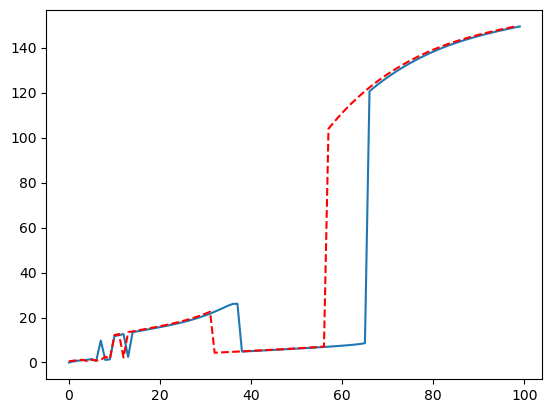

In [159]:
plt.plot(max_cdc20)
plt.plot(max_cdc20_cyc, color='red', ls='--')

In [160]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import datetime
import glob
import joblib
import shutil
import umap
sys.path.insert(0, "cellular_cycle") # add path to the model

from cell_cycle_death_model import model
from model_fxns import * # functions to evaluate simulation output; includes plotObs()


# Where to save large simulation output files
SAVE_DIR = Path(Path.home(),'ECM_mod_output/')
RED_DIR = Path(Path.home(),'ECM_mod_output/UMAP')
if not SAVE_DIR.exists():
    SAVE_DIR.mkdir()

OVERWRITE = False # Overwrite existing simulation files
SET_JPARAM = False

CURDATE = datetime.datetime.now().strftime('%Y%m%d')

GENERATE_UMAP = False

In [161]:
if SET_JPARAM:
    filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and 'psoparam' in f]
else:
    filenames = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'stoch_sim' in f and '_param_cycdi_0_0' in f]
filenames = sorted(filenames)

filenames_conds = [filenames[2], filenames[3], filenames[0],
                filenames[1], filenames[4], filenames[5]]

filenames_conds


[WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_soft_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_soft_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_int_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_int_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/stoch_sim_stiff_erl_param_cycdi_0_0.csv')]

In [162]:
if SET_JPARAM:
    filenames_ode = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'ODE_sim' in f and 'psoparam' in f]
else:
    filenames_ode = [Path(SAVE_DIR,f) for f in os.listdir(SAVE_DIR) if 'ODE_sim' in f and '_param_cycdi_0_0' in f]
    
filenames_ode = sorted(filenames_ode)

filenames_conds_ode = [filenames_ode[2], filenames_ode[3], filenames_ode[0],
                filenames_ode[1], filenames_ode[4], filenames_ode[5]]

filenames_conds_ode


[WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_soft_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_soft_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_int_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_int_erl_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_stiff_DMSO_param_cycdi_0_0.csv'),
 WindowsPath('C:/Users/olesk/ECM_mod_output/ODE_sim_stiff_erl_param_cycdi_0_0.csv')]

In [163]:
# Important params to set the window size and step time distance
init_dt = 0.1                # initial dt from the raw model output
dt = 0.1                      # dt for umap window
window = 4                    # window size in hours
time_step = 0.5               # time step between windows

#umap params
neighbs = 50
min_d = 0.01

if SET_JPARAM:
    rname = Path(RED_DIR, 'reducer_psoparams_20240513_0.1_0.1_4_0.5.sav')
else:
    rname = Path(RED_DIR, 'reducer_03_20_0.1_0.1_4_0.5.sav')

reducer = joblib.load(rname)

In [164]:
def calc_minmax(filenames, filenames_ode):
    # values to be replaced
    max_prots=[0]*18
    min_prots=[1000]*18
    
    for f in filenames:
        tmp_max=[]
        tmp_min=[]
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this now
        
        tmp_max = [prot_tmp[col].max() for col in prot_tmp]
        tmp_min = [prot_tmp[col].min() for col in prot_tmp]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]
        
    for f in filenames_ode:
        tmp_max=[]
        tmp_min=[]
        prot_tmp_ode = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        prot_tmp[prot_tmp<0] = 0 #from old extrap. method, don't think I need this
        
        tmp_max = [prot_tmp_ode[col].max() for col in prot_tmp_ode]
        tmp_min = [prot_tmp_ode[col].min() for col in prot_tmp_ode]
        
        max_prots = [max(max_prots[n], tmp_max[n]) for n in range(18)]
        min_prots = [min(min_prots[n], tmp_min[n]) for n in range(18)]  
        
    return max_prots, min_prots

In [165]:
def load_norm_data(filenames, filenames_ode, max_prots, min_prots, time_all, init_dt, dt, window, time_step, plot_phase):
     
    if plot_phase:
        plot_phase(filenames_sp, filenames_sp_ode)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_{num}.png"), bbox_inches='tight')
        plot_phase_norm(filenames_sp, filenames_sp_ode, max_prots, min_prots)
        plt.savefig(Path(SAVE_DIR, f"phaseplot_norm_{num}.png"), bbox_inches='tight')
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
        
    for (f, f_ode) in zip(filenames, filenames_ode):
        prot_tmp = pd.read_csv(f, sep=",", header=None, usecols = range(0,19))
        prot_tmp.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
        #prot_tmp = prot_tmp/200
        for ii in range(18):
            prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))
        time_re_tmp = np.empty((len(range_ind),win_len))
        time_at_tmp = np.empty((len(range_ind),1))

        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)
            tmp_at = time_tmp2['time'].iloc[n]

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp = np.append(all_prot_tmp, prot_re_tmp, axis=0)
        all_time_tmp = np.append(all_time_tmp, time_re_tmp, axis=0)
        all_time_at_tmp = np.append(all_time_at_tmp, time_at_tmp, axis=0)
        
        prot_tmp_ode = pd.read_csv(f_ode, sep=",", header=None, usecols = range(0,19))
        prot_tmp_ode.columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]
        prot_tmp_ode = prot_tmp_ode.drop(columns=['cdh1_inact'])
        for ii in range(18):
            prot_tmp_ode.iloc[:,ii] = (prot_tmp_ode.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])

        prot_re_tmp = np.empty((len(range_ind),win_len*18))


        ii=0
        for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
            tmp = prot_tmp_ode.iloc[n-int(win_len/2):n+int(win_len/2)]
            tmp=tmp.to_numpy()
            tmp=np.reshape(np.transpose(tmp),win_len*18)

            prot_re_tmp[ii,:] = np.array([tmp])
            time_re_tmp[ii,:] = np.array([tmp_t])
            time_at_tmp[ii,:] = np.array([[tmp_at]])
            ii+=1

        all_prot_tmp_ode = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
        
    return all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp
        

In [166]:
max_prots, min_prots = calc_minmax(filenames_conds, filenames_conds_ode)

In [167]:
time_tmp = np.linspace(0, 20000, 200001)
time_tmp2 = pd.DataFrame(data=time_tmp)
time_tmp2.columns = ["time"]
plot_phase = False

In [168]:
[all_prot_tmp, all_prot_tmp_ode, all_time_tmp, all_time_at_tmp] = load_norm_data(filenames_conds, filenames_conds_ode, max_prots, min_prots, time_tmp2, init_dt, dt, window, time_step, plot_phase)


In [169]:
embedding_all_prot = reducer.transform(all_prot_tmp)

In [170]:
# We don't need the full runs from the ODE solutions for the UMAP, we can use a shortened segment of the run
win_len = int(window/dt)
all_prot_tmp_ode_ab = np.empty((0,win_len*18))
ab_len = 2000
w_len = len(all_prot_tmp_ode)/len(filenames)
sp = 1
for n in range(len(filenames)):
    tmp = all_prot_tmp_ode[int(sp*w_len-ab_len):int(sp*w_len),:]
    all_prot_tmp_ode_ab = np.append(all_prot_tmp_ode_ab, tmp, axis=0)
    sp += 1

In [171]:
embedding_all_prot_ode = reducer.transform(all_prot_tmp_ode_ab)

<Axes: xlabel='Time (h)', ylabel='Concentration'>

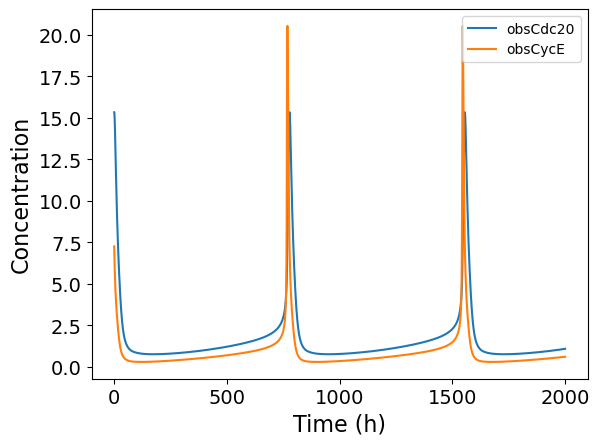

In [209]:
condition = "low_input"

t = np.linspace(0, 20000, 200001)
n = 19

# model.parameters['AKT'].value = 0.15
# model.parameters['ERK'].value = 0.1
# model.parameters['FAK'].value = 0.2
model.parameters['AKT'].value = AKTs[n]
model.parameters['ERK'].value = ERKs[n]
model.parameters['FAK'].value = FAKs[n]
# t = np.linspace(0, 50000, 500001)
sim_ode = ScipyOdeSimulator(model, t, initials=init_off_20, verbose=False, compiler='python').run() #deterministic simulation

observables=['obsCdc20', 'obsCycE']
plotObs(model=sim_ode.all, obs=observables, times=t, tpos=range(0,20000), legend=True)


In [210]:
vals = []
for obs in sim_ode.observables:
    tmp = list(obs)
    vals.append(tmp[:19])

In [211]:
len(vals[0])

19

In [175]:
def window_prot(vals):
    columns = ["skp2", "p21", "pp21", "cdh1_act", "cdh1_inact", "myc", "cycD", "cycD-p21", 
    "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
    "cycB", "cycB-p21", "cdc20"]
    
    prot_tmp = pd.DataFrame(vals, columns=columns)
    prot_tmp = prot_tmp.drop(columns=['cdh1_inact'])
    
    
    for ii in range(18):
        prot_tmp.iloc[:,ii] = (prot_tmp.iloc[:,ii] - min_prots[ii])/(max_prots[ii] - min_prots[ii])
    
    win_len = int(window/dt)
    all_prot_tmp = np.empty((0,win_len*18))     #careful, this could end up being massive 
    all_prot_tmp_ode = np.empty((0,win_len*18))
    all_time_tmp = np.empty((0,win_len))
    all_time_at_tmp = np.empty((0,1))
    range_ind = np.arange(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt))
    
    prot_re_tmp = np.empty((len(range_ind),win_len*18))
    time_re_tmp = np.empty((len(range_ind),win_len))
    time_at_tmp = np.empty((len(range_ind),1))
    
    ii=0
    for n in range(int(win_len/2),int(len(time_tmp2)-(int(win_len/2))),int(time_step/dt)):
        tmp = prot_tmp.iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp_t = time_tmp2['time'].iloc[n-int(win_len/2):n+int(win_len/2)]
        tmp=tmp.to_numpy()
        tmp=np.reshape(np.transpose(tmp),win_len*18)
        tmp_at = time_tmp2['time'].iloc[n]
    
        prot_re_tmp[ii,:] = np.array([tmp])
        time_re_tmp[ii,:] = np.array([tmp_t])
        time_at_tmp[ii,:] = np.array([[tmp_at]])
        ii+=1
    
    ode_out = np.append(all_prot_tmp_ode, prot_re_tmp, axis=0)
    ode_end = ode_out[ode_out.shape[0]-2000:]

    return ode_end


In [177]:
low_input_end = window_prot(vals)

In [188]:
off_60_end = window_prot(vals)

In [200]:
on_60_end = window_prot(vals)

In [212]:
off_20_end = window_prot(vals)

In [178]:
embedding_low_input_ode = reducer.transform(low_input_end)

In [189]:
embedding_off_60_end = reducer.transform(off_60_end)

In [201]:
embedding_on_60_end = reducer.transform(on_60_end)

In [213]:
embedding_off_20_end = reducer.transform(off_20_end)

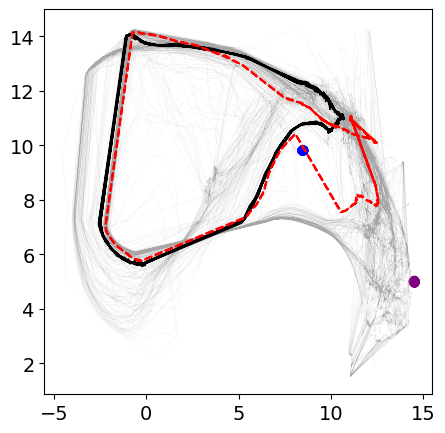

In [227]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
trk_len = int(len(embedding_all_prot)/len(filenames_conds))
trk_len_ode = int(len(embedding_all_prot_ode)/len(filenames_conds))
n=1
n1=2
plt.plot(embedding_all_prot[n*trk_len:n1*trk_len,0], embedding_all_prot[n*trk_len:n1*trk_len,1], 
         lw=0.05, alpha=0.7, c='gray')
plt.plot(embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,0], embedding_all_prot_ode[n*trk_len_ode:n1*trk_len_ode,1], 
         lw=1, alpha=1, c='black')
plt.scatter(embedding_low_input_ode[1900:,0], embedding_low_input_ode[1900:,1], c='purple')
plt.scatter(embedding_off_60_end[1900:,0], embedding_off_60_end[1900:,1], c='blue')
plt.plot(embedding_on_60_end[1500:,0], embedding_on_60_end[1500:,1], c='red', ls='--')
# plt.plot(embedding_off_20_end[:,0], embedding_off_20_end[:,1], c='green')


In [231]:
embedding_low_input_ode

array([[ 7.2585363, 10.617411 ],
       [ 7.27193  , 10.625846 ],
       [ 7.240286 , 10.614235 ],
       ...,
       [ 7.272058 , 10.627069 ],
       [ 7.2484283, 10.64789  ],
       [ 7.242865 , 10.632918 ]], dtype=float32)